<a href="https://colab.research.google.com/github/senchiao/HRRR_plots/blob/main/ESRL_SST_TimeSeries.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 35 years of 1/4 degree SST data from NOAA-ESRL

### Next line allows for graphics to appear directly below cell in which the figure(s) is (are) generated

In [1]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


### Import the three libraries we need for this script

In [2]:
!pip install netCDF4
import matplotlib.pyplot as plt
import netCDF4 as nc
from IPython.display import clear_output

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 15.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 19.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [netCDF4]


### Connect to the OpenDAP server and open a file handle to the SST data file

In [3]:
ncf = nc.Dataset ("http://www.esrl.noaa.gov/psd/thredds/dodsC/Aggregations/OISSThires/sst.mean.nc")

### List the variables in the file.
### (For all the lines that follow, uncomment each of the print statements which appear below when you run the script, and comment out each of the clear_output() lines.)

In [4]:
ncv = ncf.variables
for var in ncv.keys():
    print (var)
    #clear_output()

lat
lon
time
sst


## Each of these variables are Python dictionary keys.  Here we assign one to a variable to hold the array of sst values.  Uncomment the print statetment to see the type and shape of this variable.

In [5]:
sst = ncv['sst']
#print sst

### Now do the same for the other three variables.  Choose a single point at which we will use to create the time series of SST values.

In [6]:
lat = ncv['lat']
lon = ncv['lon']
time = ncv['time']
y = 381
x = 920
print (lat[y])
print (lon[x])

5.375
230.125


### Uncomment these next three lines to see the structure of the time variable, as well as its earliest and latest value.  In this case, these values represent the # of days since Jan 1, 1800.

In [7]:
print (time)
print (time[0])
print (time[-1])

<class 'netCDF4.Variable'>
float64 time(time)
    long_name: Time
    units: days since 1800-01-01 00:00:00
    delta_t: 0000-00-01 00:00:00
    avg_period: 0000-00-01 00:00:00
    axis: T
    actual_range: [82180. 82544.]
    _ChunkSizes: 512
unlimited dimensions: 
current shape = (16506,)
filling off
66352.0
82857.0


### Now, print out the value of SST at the point we chose above, for the most recent day.  Since the file gets updated in near-real-time at ESRL, this value should change if you run this script again at a later date!

In [8]:
print (sst[[-1],y,x])

[29.619999]


# Despite there being 1440x720x12344 = 12,798,259,200 values in this dataset, it takes very litle time, probably less than a second, to obtain the value.  Imagine how long it would have taken to download it, assuming you had the disk space to store it!


### Now, prepare for the time series. If we wanted to plot the entire time period, that would in fact take some time.  Here, we choose the most recent ten years, and sample every fifteen days, which should be sufficient to ascertain the multi-year nature of the SST variability at this point.  Assuming a low-end broadband connection, this should take less than a minute.

In [10]:
timeSub = time[-3655:-1:15]
# Request the data points individually in a list comprehension to bypass complex remote striding limitations
sstSub = np.array([sst[int(t_idx), y, x] for t_idx in range(len(time) - 3655, len(time) - 1, 15)])

In [11]:
print(f"The value of x is: {x}")
print(f"The value of y is: {y}")

The value of x is: 920
The value of y is: 381


In [13]:
timeSub = time[-3655:-1:15]
# Request the data points individually in a list comprehension to bypass complex remote striding limitations
sstSub = np.array([sst[int(t_idx), 381, 920] for t_idx in range(len(time) - 3655, len(time) - 1, 15)])

### Uncomment these print statments to check the start and end dates of our ten-year subset.

In [14]:
print (timeSub.shape)
print (timeSub [0])
print (timeSub [-1])

(244,)
79203.0
82848.0


## We are ready to create the time series plot.  Be sure to comment out the last line (clear_output() ) or else you will not see the figure!

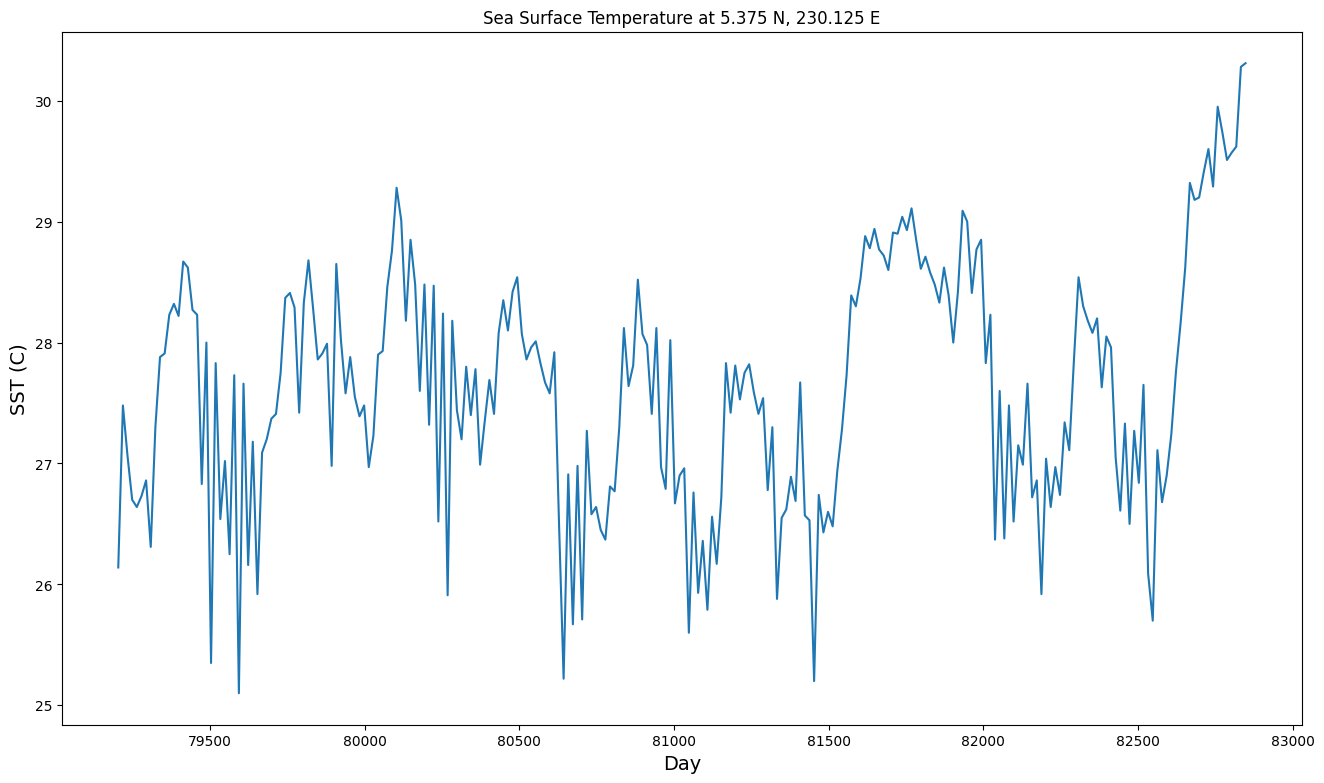

In [15]:
plt.figure(figsize=(16,9))
plt.plot(timeSub,sstSub)
titleStr = 'Sea Surface Temperature at '+str(lat[y])+' N, '+str(lon[x])+' E'
plt.title(titleStr)
plt.xlabel('Day',fontsize=14)
plt.ylabel('SST (C)',fontsize=14)
plt.show()
# Comment out this next line in order to see the graphic
#clear_output()

# So in just a dozen or so lines of code, we have queried a large data set and (assuming a functional internet connection) gotten our result likely in less than a minute or so.  Of course we could (and should) make a more informative x-axis label, and make the script more portable, but this is just a starting point!